# 09 · Feature plan and modelling readiness

What the EDA means for modelling: which features to use and how to transform them, which are redundant, whether regions look alike, how to validate, and which inputs are risky under the rules. Saves `eda_outputs/feature_plan.csv` and `eda_outputs/model_ready.parquet`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data").exists())
DATA, OUT, ANALYSIS = ROOT / "data", ROOT / "eda_outputs", ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))
df = pd.read_parquet(OUT / "base_table.parquet")

def box_by_region(ax, col, log=False, title="", ylabel=None, data=None):
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. Candidate features and what to do with each

{'POIs': 7, 'buildings': 7, 'context': 6, 'hazard': 4, 'roads': 7, 'vulnerability': 3}

              feature         group                    transform  missing %  skew
         bldg_per_km2     buildings                  yeo-johnson       0.02  0.77
          bldg_per_hu     buildings cap at 99th pct, yeo-johnson       0.84 63.39
           share_msft     buildings               none (bounded)       0.02  0.52
            share_osm     buildings               none (bounded)       0.02 -0.33
           tiny_share     buildings                  yeo-johnson       0.02  2.42
         height_share     buildings               none (bounded)       0.02 -0.99
  bldg_area_median_m2     buildings                  yeo-johnson       0.02  8.83
      road_km_per_km2         roads                         none       0.02  0.10
 hwy_share_of_road_km         roads               none (bounded)       0.02  1.29
          road_km_hwy         roads                        log1p       0.00  4.93
         h

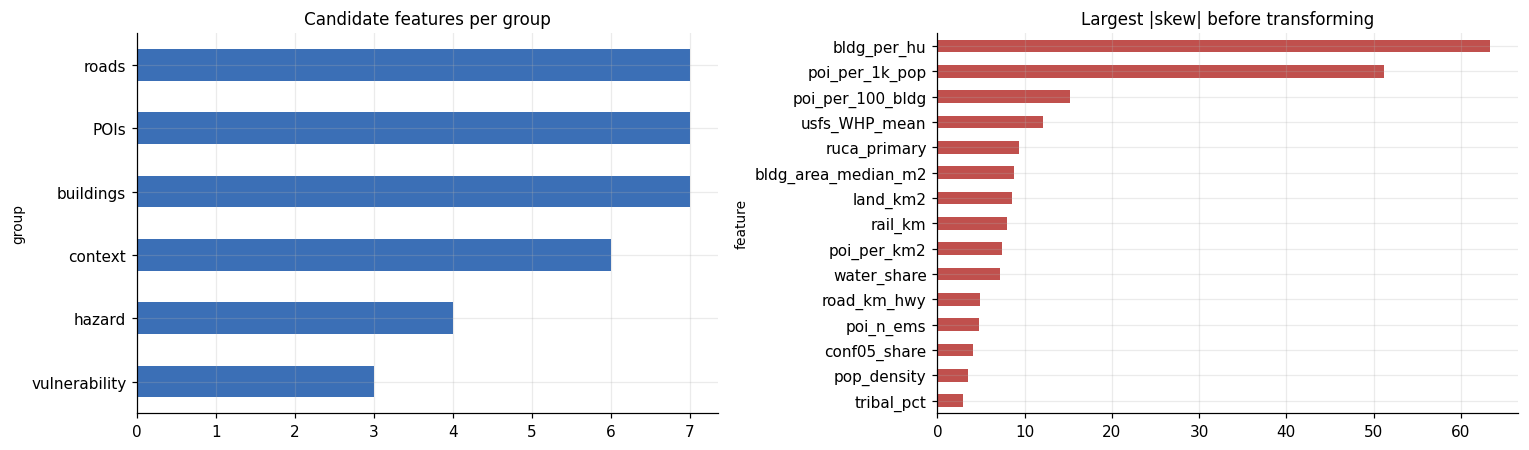

In [2]:
from sklearn.preprocessing import PowerTransformer
plan = pd.DataFrame([
 # feature, group, transform, note
 ("bldg_per_km2", "buildings", "yeo-johnson", "density of buildings"), ("bldg_per_hu", "buildings", "cap at 99th pct, yeo-johnson", "tiny denominators give extreme values; missing when no housing units"),
 ("share_msft", "buildings", "none (bounded)", "how much of the reference is already in Overture"), ("share_osm", "buildings", "none (bounded)", "mirror of share_msft (see redundancy check below)"),
 ("tiny_share", "buildings", "yeo-johnson", "footprints under 30 m2"), ("height_share", "buildings", "none (bounded)", "attribute completeness"), ("bldg_area_median_m2", "buildings", "yeo-johnson", "typical footprint"),
 ("road_km_per_km2", "roads", "none", "already symmetric"), ("hwy_share_of_road_km", "roads", "none (bounded)", "highway classes the road component uses"), ("road_km_hwy", "roads", "log1p", "0 = no highway, a defining case for the road component"),
 ("has_motorway", "roads", "binary", "presence of each highway class"), ("has_trunk", "roads", "binary", "presence of each highway class"), ("rail_km", "roads", "log1p", "mostly zero"), ("no_transit", "roads", "binary", "half of tracts"),
 ("poi_per_km2", "POIs", "log1p", "POI density"), ("poi_per_1k_pop", "POIs", "cap, log1p", "tiny populations give extreme values"), ("poi_per_100_bldg", "POIs", "log", "places per building"),
 ("poi_n_fire", "POIs", "count / binary", "fire stations, the facility type that carries the POI component"), ("poi_n_ems", "POIs", "binary", "very rare"), ("poi_n_school", "POIs", "count", "schools"), ("conf05_share", "POIs", "none (bounded)", "POI confidence"),
 ("pop_density", "context", "yeo-johnson", "density of people"), ("pct_urban", "context", "none (bounded)", "almost binary"), ("ruca_primary", "context", "ordinal", "rural-urban commuting code"), ("land_km2", "context", "log", "tract size"), ("water_share", "context", "none (bounded)", "46% zero"),
 ("svi_overall", "vulnerability", "none", "missing for 1-2%: impute plus flag"), ("cvi_overall", "vulnerability", "none", "climate vulnerability"), ("tribal_pct", "vulnerability", "none (bounded)", "share inside tribal land"),
 ("usfs_WHP_mean", "hazard", "yeo-johnson", "behaves like a ruralness measure"), ("usdm_summer_dsci", "hazard", "none", "regional"), ("gehe_wbgt28_days_mean", "hazard", "none", "regional, near-zero in Eastern WA"), ("pmdi_mean", "hazard", "none", "regional"),
 ("housing_units", "context", "log1p", "ACS count, a permitted reference"),
], columns=["feature", "group", "transform", "note"])
df["has_motorway"] = df.road_km_motorway > 0; df["has_trunk"] = df.road_km_trunk > 0
num = plan.feature.tolist(); X = df[num].astype(float).replace([np.inf, -np.inf], np.nan)
plan["missing %"] = (X.isna().mean() * 100).round(2).values; plan["skew"] = X.apply(lambda s: stats.skew(s.dropna())).round(2).values
print(plan.groupby("group").size().to_dict()); print(); print(plan[["feature", "group", "transform", "missing %", "skew"]].to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2)); plan.groupby("group").size().sort_values().plot.barh(ax=ax[0], color="#3b6fb6"); ax[0].set_title("Candidate features per group"); plan.set_index("feature")["skew"].abs().sort_values().tail(15).plot.barh(ax=ax[1], color="#c0504d"); ax[1].set_title("Largest |skew| before transforming")
plt.tight_layout(); plt.show(); OUT.mkdir(exist_ok=True); plan.to_csv(OUT / "feature_plan.csv", index=False)

**Takeaway:** 34 candidate features in six groups (buildings 7, roads 7, POIs 7, context 6, hazards 4, vulnerability 3). Three ratios are extremely skewed because of tiny denominators: buildings per housing unit (skew 63), POIs per 1,000 residents (51) and POIs per 100 buildings (15), so they need capping plus a power transform. Missing values are rare (at most 0.84%), so imputation plus a missing flag is enough. The plan is saved to `eda_outputs/feature_plan.csv`.

## 2. Redundancy: which features say the same thing?

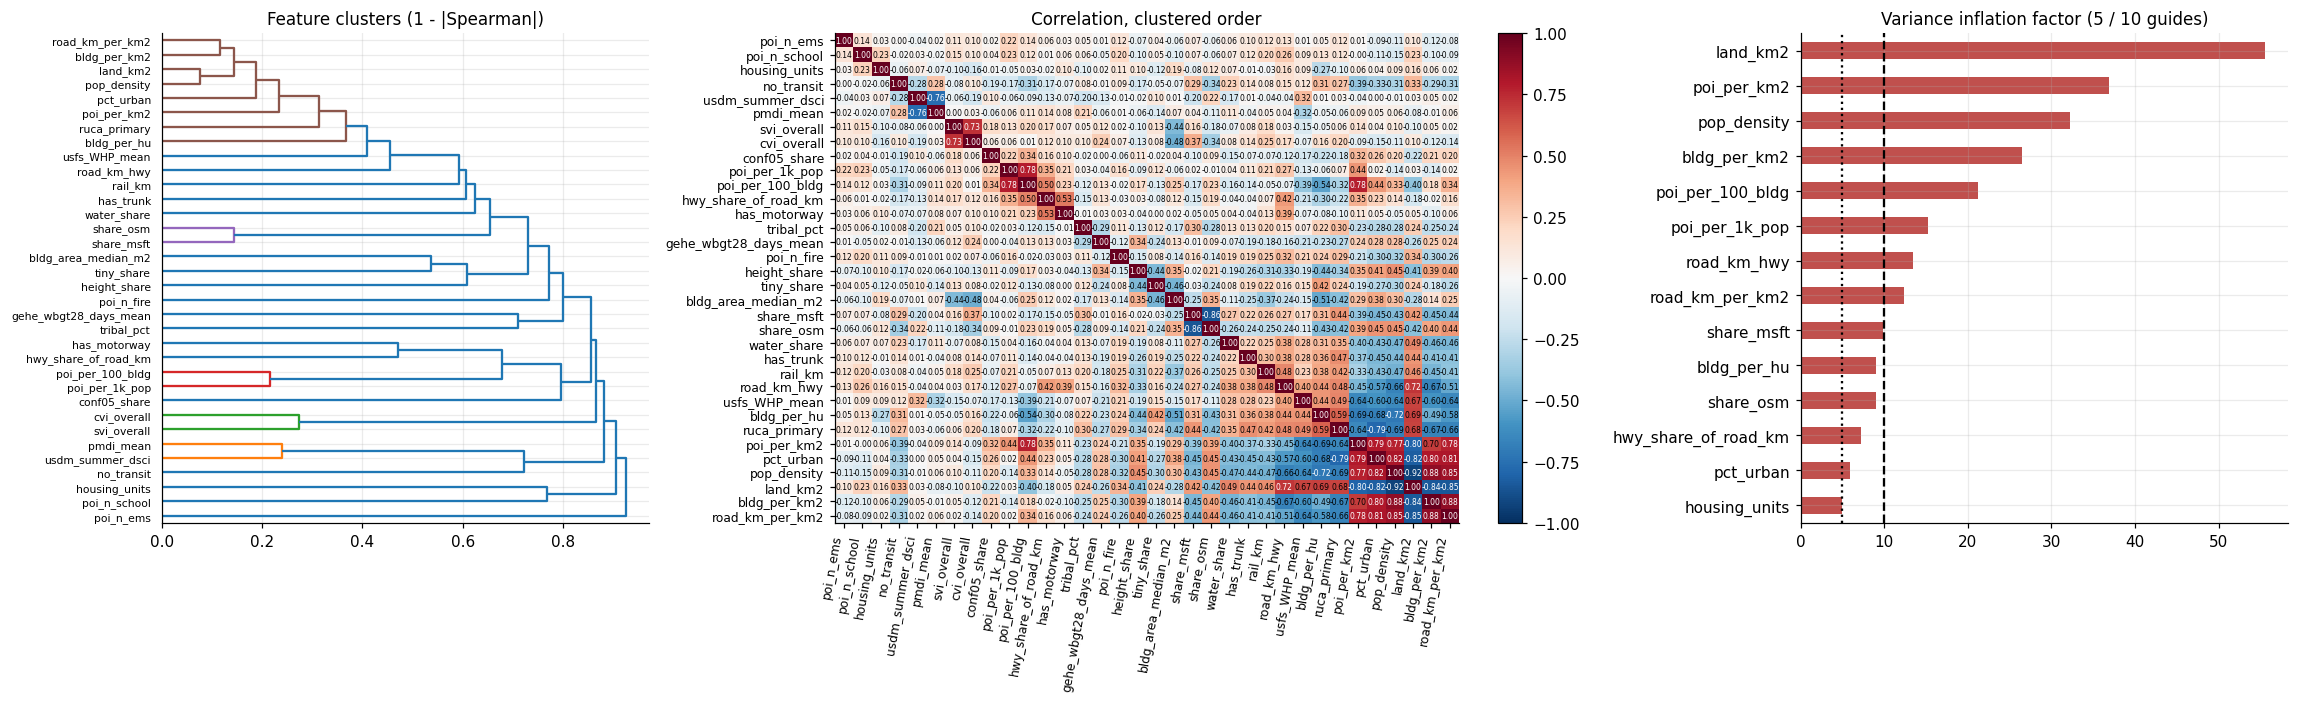

4 pairs with |rho| > 0.85:
  pop_density ~ land_km2: -0.92
  bldg_per_km2 ~ road_km_per_km2: +0.88
  bldg_per_km2 ~ pop_density: +0.88
  share_msft ~ share_osm: -0.86

VIF > 10: {'bldg_per_km2': 26.5, 'road_km_per_km2': 12.3, 'road_km_hwy': 13.5, 'poi_per_km2': 36.9, 'poi_per_1k_pop': 15.3, 'poi_per_100_bldg': 21.3, 'pop_density': 32.3, 'land_km2': 55.5}


In [3]:
from scipy.cluster import hierarchy as hc
from statsmodels.stats.outliers_influence import variance_inflation_factor
Z = PowerTransformer("yeo-johnson").fit_transform(X.fillna(X.median())); Z = pd.DataFrame(Z, columns=num)
cm = Z.corr(method="spearman"); link = hc.linkage(hc.distance.squareform(1 - cm.abs().values, checks=False), "average"); order = hc.leaves_list(link)
pairs = [(a, b, cm.loc[a, b]) for i, a in enumerate(num) for b in num[i + 1:] if abs(cm.loc[a, b]) > .85]
vif = pd.Series([variance_inflation_factor(Z.assign(c=1).values, i) for i in range(len(num))], num)
fig, ax = plt.subplots(1, 3, figsize=(21, 6.5), gridspec_kw={"width_ratios": [1, 1.6, 1]}); hc.dendrogram(link, labels=num, orientation="right", ax=ax[0], leaf_font_size=7, color_threshold=.4); ax[0].set_title("Feature clusters (1 - |Spearman|)")
plt.colorbar(heat(ax[1], cm.iloc[order, order], fs=5, rot=80), ax=ax[1]); ax[1].set_title("Correlation, clustered order"); vif.sort_values().tail(14).plot.barh(ax=ax[2], color="#c0504d"); ax[2].axvline(10, color="k", ls="--"); ax[2].axvline(5, color="k", ls=":"); ax[2].set_title("Variance inflation factor (5 / 10 guides)")
plt.tight_layout(); plt.show(); print(f"{len(pairs)} pairs with |rho| > 0.85:"); [print(f"  {a} ~ {b}: {r:+.2f}") for a, b, r in sorted(pairs, key=lambda x: -abs(x[2]))[:12]]; print("\nVIF > 10:", vif[vif > 10].round(1).to_dict())

**Takeaway:** several features say the same thing. Four pairs exceed |rho| 0.85: population density and land area (-0.92), building density with road density (0.88) and with population density (0.88), and the Microsoft and OSM shares (-0.86). Eight features have VIF above 10 (land area 55, POIs per km2 37, population density 32, building density 27, POIs per 100 buildings 21). For linear models keep one density measure and one source share (drop `share_osm`); tree models tolerate this but their importances will be split.

## 3. Do the regions look alike? (domain shift)

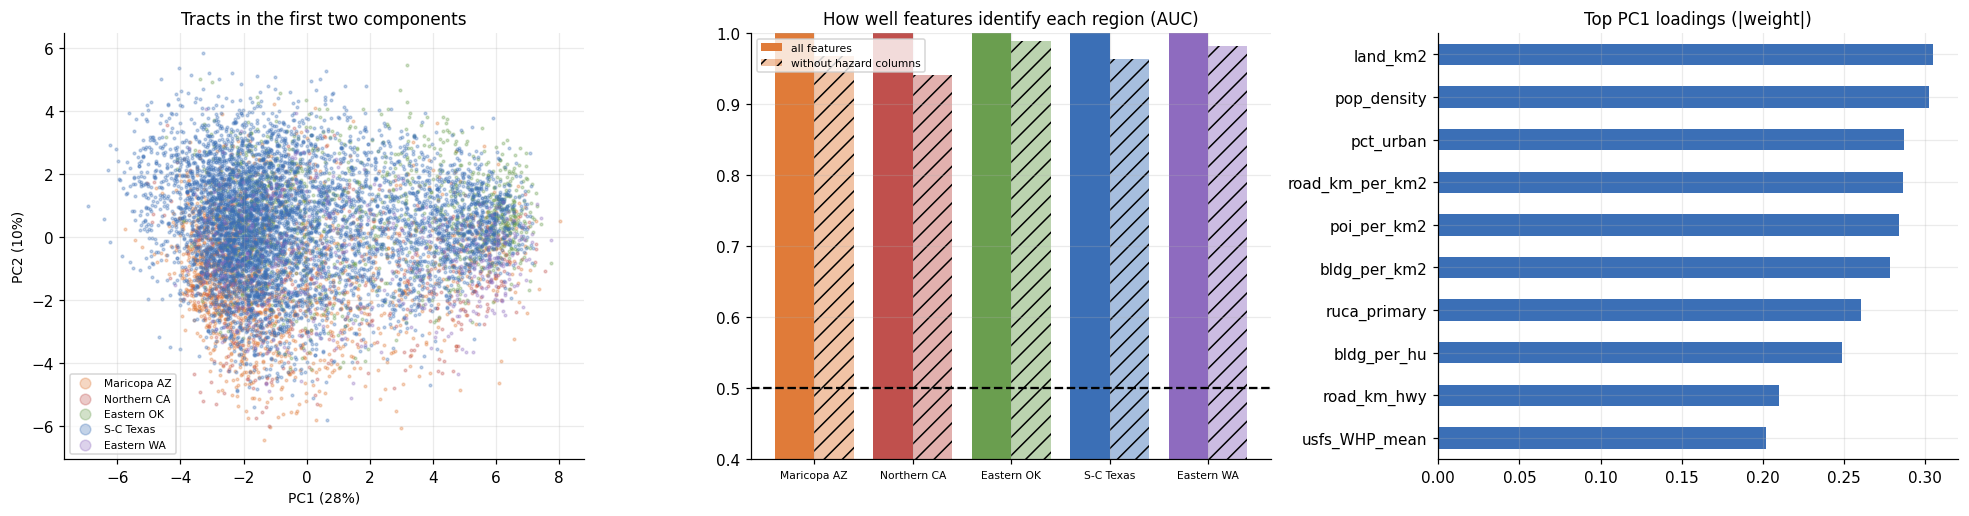

region AUC, all features: {'Maricopa AZ': 1.0, 'Northern CA': 1.0, 'Eastern OK': 1.0, 'S-C Texas': 1.0, 'Eastern WA': 1.0} | accuracy 0.997 (chance = 0.61 by predicting Texas)
region AUC, without hazard columns: {'Maricopa AZ': 0.968, 'Northern CA': 0.941, 'Eastern OK': 0.989, 'S-C Texas': 0.964, 'Eastern WA': 0.983} | accuracy 0.867


In [4]:
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score
pc = PCA(2).fit(Z); P2 = pc.transform(Z); proba = cross_val_predict(HistGradientBoostingClassifier(max_depth=3, max_iter=120, random_state=0), Z, df.region, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")
cls = sorted(df.region.unique()); auc = {r: roc_auc_score(df.region == r, proba[:, cls.index(r)]) for r in REG}; acc = (np.array(cls)[proba.argmax(1)] == df.region.values).mean()
nh = [c for c in num if c not in plan.feature[plan.group.isin(["hazard"])].tolist()]; proba2 = cross_val_predict(HistGradientBoostingClassifier(max_depth=3, max_iter=120, random_state=0), Z[nh], df.region, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")
auc2 = {r: roc_auc_score(df.region == r, proba2[:, cls.index(r)]) for r in REG}; acc2 = (np.array(cls)[proba2.argmax(1)] == df.region.values).mean()
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for r in REG: m = df.region == r; ax[0].scatter(P2[m, 0], P2[m, 1], s=3, alpha=.3, color=COL[r], label=NAME[r])
ax[0].set(xlabel=f"PC1 ({pc.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pc.explained_variance_ratio_[1]:.0%})", title="Tracts in the first two components"); ax[0].legend(markerscale=4, fontsize=7)
xx = np.arange(5); ax[1].bar(xx - .2, [auc[r] for r in REG], .4, color=[COL[r] for r in REG], label="all features"); ax[1].bar(xx + .2, [auc2[r] for r in REG], .4, color=[COL[r] for r in REG], alpha=.45, hatch="//", label="without hazard columns"); ax[1].set_xticks(xx); ax[1].set_xticklabels([NAME[r] for r in REG]); ax[1].legend(fontsize=7); ax[1].axhline(.5, color="k", ls="--"); ax[1].set_ylim(.4, 1); ax[1].set_title("How well features identify each region (AUC)"); ax[1].tick_params(axis="x", labelsize=7)
ld = pd.Series(pc.components_[0], num).abs().sort_values().tail(10); ld.plot.barh(ax=ax[2], color="#3b6fb6"); ax[2].set_title("Top PC1 loadings (|weight|)")
plt.tight_layout(); plt.show(); print("region AUC, all features:", {NAME[r]: round(v, 3) for r, v in auc.items()}, "| accuracy", round(acc, 3), "(chance = 0.61 by predicting Texas)"); print("region AUC, without hazard columns:", {NAME[r]: round(v, 3) for r, v in auc2.items()}, "| accuracy", round(acc2, 3))

**Takeaway:** the regions are easy to tell apart: a classifier identifies the region from the features with accuracy 0.997 (61% would come from always guessing Texas). Without the hazard columns it still reaches 0.87 accuracy and AUC 0.94-0.99, so regions differ in the coverage features themselves, not only in climate. A model can therefore learn region identity cheaply, and predicting a region it has never seen is extrapolation.

## 4. Validation design: random folds versus holding out a region

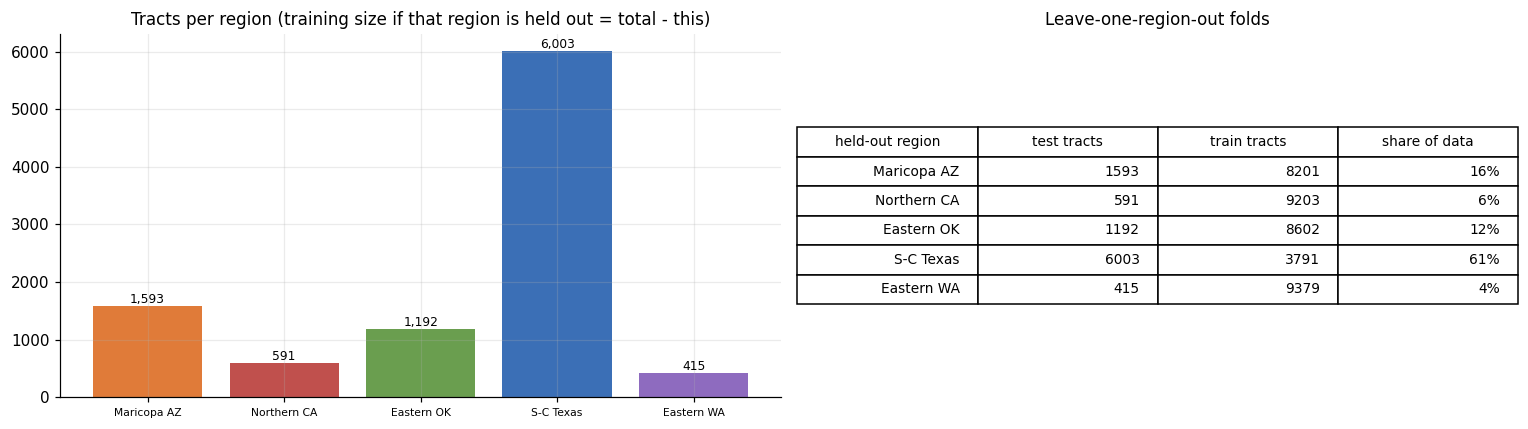

random 5-fold: each fold ~ 1958 tracts, all regions in every fold | leave-region-out: Texas fold leaves 3791 tracts to learn from


In [5]:
from sklearn.model_selection import KFold, LeaveOneGroupOut
fig, ax = plt.subplots(1, 2, figsize=(14, 4)); cnt = df.region.value_counts().reindex(REG)
ax[0].bar([NAME[r] for r in REG], cnt, color=[COL[r] for r in REG]); ax[0].set_title("Tracts per region (training size if that region is held out = total - this)"); ax[0].tick_params(axis="x", labelsize=7)
for i, v in enumerate(cnt): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
rows = [(NAME[r], int(cnt[r]), int(len(df) - cnt[r]), f"{cnt[r] / len(df):.0%}") for r in REG]; ax[1].axis("off"); tb = ax[1].table(cellText=rows, colLabels=["held-out region", "test tracts", "train tracts", "share of data"], loc="center"); tb.auto_set_font_size(False); tb.set_fontsize(9); tb.scale(1, 1.5); ax[1].set_title("Leave-one-region-out folds")
plt.tight_layout(); plt.show()
print("random 5-fold: each fold ~", len(df) // 5, "tracts, all regions in every fold | leave-region-out: Texas fold leaves", len(df) - int(cnt["south-central-tx"]), "tracts to learn from")

**Takeaway:** random 5-fold folds hold about 1,958 tracts each with every region represented, which rewards learning region identity. Holding a region out is the harder and more honest test: the Texas fold leaves only 3,791 tracts (39%) to learn from. Report both, and check whether the competition's test tracts come from the same five regions before trusting either number.

## 5. Rules and leakage checks on the inputs

                                                        input                                                                                      status                                    decision
                                          housing_units (ACS)                                                          permitted reference in the package                                        keep
    Overture aggregates (buildings, roads, POIs, rail, infra)                                                                     the layers being scored                                        keep
                     strata (SVI, CVI, RUCA, tribal, hazards)                                                                    permitted context tables                                        keep
usfs_BuildingCount_sum / usfs_HUCount_sum / usfs_PopCount_sum building counts from a USFS layer; provenance and permissibility are an open rules question            exploration only until confirmed
          

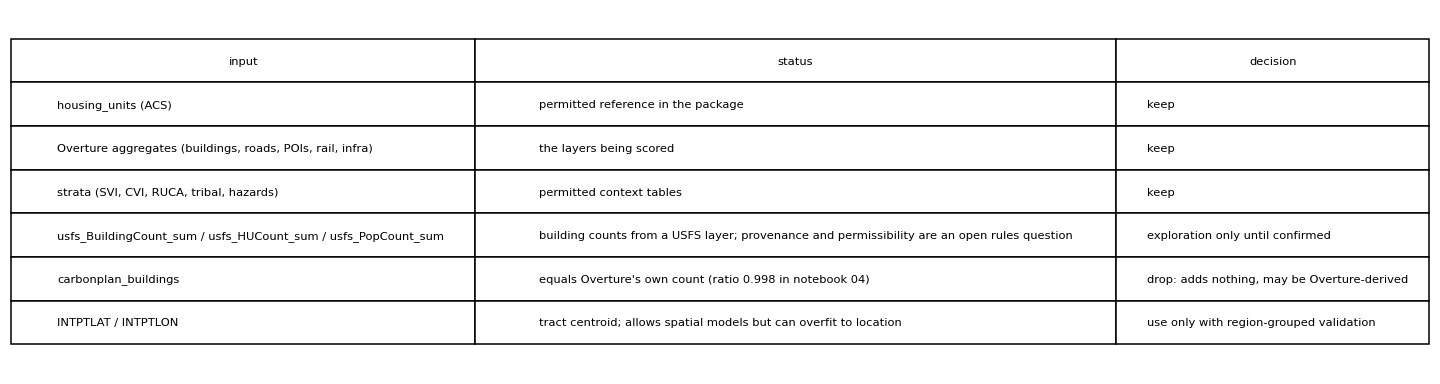

In [6]:
chk = pd.DataFrame([
 ("housing_units (ACS)", "permitted reference in the package", "keep"), ("Overture aggregates (buildings, roads, POIs, rail, infra)", "the layers being scored", "keep"),
 ("strata (SVI, CVI, RUCA, tribal, hazards)", "permitted context tables", "keep"),
 ("usfs_BuildingCount_sum / usfs_HUCount_sum / usfs_PopCount_sum", "building counts from a USFS layer; provenance and permissibility are an open rules question", "exploration only until confirmed"),
 ("carbonplan_buildings", "equals Overture's own count (ratio 0.998 in notebook 04)", "drop: adds nothing, may be Overture-derived"),
 ("INTPTLAT / INTPTLON", "tract centroid; allows spatial models but can overfit to location", "use only with region-grouped validation")], columns=["input", "status", "decision"])
d = df[["usfs_BuildingCount_sum", "carbonplan_buildings", "bldg_n"]].dropna(); rho = d.corr(method="spearman")
print(chk.to_string(index=False)); print("\nSpearman with Overture building count:", rho.loc["bldg_n", ["usfs_BuildingCount_sum", "carbonplan_buildings"]].round(3).to_dict())
fig, ax = plt.subplots(figsize=(8, 3.6)); ax.axis("off"); tb = ax.table(cellText=chk.values, colLabels=chk.columns, loc="center", cellLoc="left"); tb.auto_set_font_size(False); tb.set_fontsize(7.5); tb.scale(1, 2.0); [tb.auto_set_column_width(i) for i in range(3)]
plt.tight_layout(); plt.show()

**Takeaway:** the USFS building count correlates 0.956 with Overture's own count and its provenance is an open rules question, so it is exploration only. CarbonPlan's count correlates 1.000 with Overture's and adds nothing, so drop it. Centroid coordinates enable spatial models but should only be used with region-grouped validation. ACS housing units, the Overture aggregates and the strata tables are the safe inputs.

## 6. Save the model-ready feature table

In [7]:
ready = pd.concat([df[["GEOID", "region"]].reset_index(drop=True), Z.add_prefix("z_")], axis=1); miss = X.isna().add_suffix("_missing"); keepm = miss.columns[miss.mean() > .001]
ready = pd.concat([ready, miss[keepm].astype(int).reset_index(drop=True)], axis=1); ready.to_parquet(OUT / "model_ready.parquet", index=False)
print("saved model_ready.parquet:", ready.shape, "| missing-value flags kept:", list(keepm), "| any NaN in z columns:", bool(ready.filter(like="z_").isna().any().any()))

saved model_ready.parquet: (9794, 40) | missing-value flags kept: ['bldg_per_hu_missing', 'poi_per_1k_pop_missing', 'pct_urban_missing', 'svi_overall_missing'] | any NaN in z columns: False


**Takeaway:** saved `eda_outputs/model_ready.parquet`: 9,794 rows, the 34 transformed features (`z_` columns), four missing-value flags (buildings per home, POIs per resident, pct_urban, SVI) and the keys; no missing values remain in the feature columns. There is still no target, since it is hidden.